# Tracking in the NA62 GigaTracker with a Transformer

Full pipeline: from the ROOT ntuple to reconstructed tracks.

1. **Setup** of the environment
2. **Pre-processing**: from the ntuple to input and ground-truth matrices
3. **Dataset and DataLoader**
4. **Model**: Transformer encoder + pair classifier, in PyTorch Lightning
5. **Training** and checkpoint
6. **Post-processing and evaluation**: from scores to tracks, efficiency and purity
7. **Visualizations** of critical cases

## 0. Setup

### 0.1 Virtual environment

- **Locally** (Jupyter / VS Code): create a venv, install the dependencies and register it as a kernel. Then select the `gtk-tutorial` kernel and restart the notebook.
- **On Colab**: the kernel always uses the system Python, so a venv would not be used. Skip this cell and run 0.2 directly.

In [80]:
# # Local only: run once from the Tutorial/ folder, then select the "gtk-tutorial" kernel.
# # Python 3.11 is required (torch 2.1.2 has no wheels for newer Python versions).
# !python3.11 -m venv .venv
# !.venv/bin/pip install --upgrade pip
# !.venv/bin/pip install -r requirements.txt
# !.venv/bin/python -m ipykernel install --user --name gtk-tutorial --display-name "gtk-tutorial"

### 0.2 Dependencies (Colab)

In [81]:
# import sys
# IN_COLAB = "google.colab" in sys.modules
# if IN_COLAB:
#     !pip install -q pytorch-lightning==2.5.1 focal-loss-torch uproot awkward plotly onnx onnxruntime

### 0.3 Imports, seed and device

In [82]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import pytorch_lightning as pl
import uproot
import awkward as ak
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from focal_loss.focal_loss import FocalLoss
from tqdm import tqdm
import onnxruntime
import utilities   # long helper functions (plots, metric tables), see Tutorial/utilities.py
import inspect

# One call seeds python, numpy and torch (and the DataLoader workers)
SEED = 42
pl.seed_everything(SEED, workers=True)

# CPU: the model is small and a GPU is usually not available
DEVICE = "cpu"
torch.set_num_threads(4)   # avoid oversubscribing shared machines / Colab

print(f"torch {torch.__version__} | lightning {pl.__version__} | device: {DEVICE}")


Seed set to 42


torch 2.1.2+cu121 | lightning 2.5.1 | device: cpu


### 0.4 Configuration

All hyperparameters in a single dictionary, instead of the YAML file. The model hyperparameters match the pre-trained checkpoint used in section 4.3: changing them means training from scratch.

In [83]:
config = {
    "data": {
        "ntuple_path": "data/Small_data.root",
        "tree_path": "PnnOneTrackEventSelection/GTtree",
        "split": {"train": 0.6, "val": 0.2, "test": 0.2},
        "batch_size": 32,
    },
    "model": {
        "input_dim": 4,              # cl_x, cl_y, GTKstation, cl_time
        "d_model": 32,
        "num_head": 2,
        "num_layers": 2,
        "hidden_dim_classifier": 64,
        "dropout": 0.1,
        "output_dim": 2,             # [not connected, connected]
        "device": DEVICE,
    },
    "training": {
        "loss": "Focal",             # "Focal" or "CrossEntropy"
        "lr": 1e-4,
        "lr_scheduler_step_size": 50,
        "lr_scheduler_gamma": 0.5,
        "num_epochs": 2,
        "patience": 5,
        "checkpoint_dir": "checkpoints",
    },
}

## 1. Pre-processing: from the ntuple to tensors

### 1.1 Reading the ntuple with `uproot`

In [84]:
tree = uproot.open(config["data"]["ntuple_path"])[config["data"]["tree_path"]]
print(f"{tree.num_entries} events")
tree.show()   # branch names and types



20000 events
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
ncl_x                | int32_t                  | AsDtype('>i4')
cl_x                 | float[]                  | AsJagged(AsDtype('>f4'))
ncl_y                | int32_t                  | AsDtype('>i4')
cl_y                 | float[]                  | AsJagged(AsDtype('>f4'))
ncl_time             | int32_t                  | AsDtype('>i4')
cl_time              | float[]                  | AsJagged(AsDtype('>f4'))
nGTKstation          | int32_t                  | AsDtype('>i4')
GTKstation           | int32_t[]                | AsJagged(AsDtype('>i4'))
ncl_kinepart         | int32_t                  | AsDtype('>i4')
cl_kinepart          | int32_t[]                | AsJagged(AsDtype('>i4'))
nset_cl_kinepart     | int32_t                  | AsDtype('>i4')
set_cl_kinepart      | int32_t[]                | AsJagged(A

In [85]:
# One awkward array per branch: one entry per event, variable length per hit
events = tree.arrays(["cl_x", "cl_y", "cl_time", "GTKstation", "cl_kinepart", "KTAGTime", "eventNumber", "burst"])
print(events.type)
print("hits per event:", ak.num(events.cl_x)[:10].tolist())

20000 * {cl_x: var * float32, cl_y: var * float32, cl_time: var * float32, GTKstation: var * int32, cl_kinepart: var * int32, KTAGTime: float32, eventNumber: int32, burst: int32}
hits per event: [66, 50, 58, 29, 75, 34, 88, 59, 30, 36]


### 1.2 An event as a table of hits

In [86]:
def event_to_df(events, index):
    """One event of the ntuple as a table: one row per hit."""
    event = events[index]
    return pd.DataFrame({
        "cl_x": ak.to_numpy(event.cl_x),
        "cl_y": ak.to_numpy(event.cl_y),
        "cl_time": ak.to_numpy(event.cl_time),
        "GTKstation": ak.to_numpy(event.GTKstation),
        "cl_kinepart": ak.to_numpy(event.cl_kinepart),   # truth: id of the particle that made the hit
    })

df = event_to_df(events, index=5)
df

,cl_x,cl_y,cl_time,GTKstation,cl_kinepart
0,25.064619,3.687605,14.752574,0,14
1,13.769900,7.002295,5.255361,0,65
2,4.272300,8.514646,17.347830,0,26
3,6.842540,-10.088735,17.580618,0,64
4,10.138700,-12.493025,1.562995,0,71
5,-2.949780,-5.275995,11.673615,0,67
6,-4.749780,-5.273655,9.103390,0,0
7,-22.543060,-1.050515,10.265525,0,68
8,-21.356501,-9.452075,8.199196,0,81
9,25.096085,3.511250,15.453855,1,14


### 1.3 Event selection

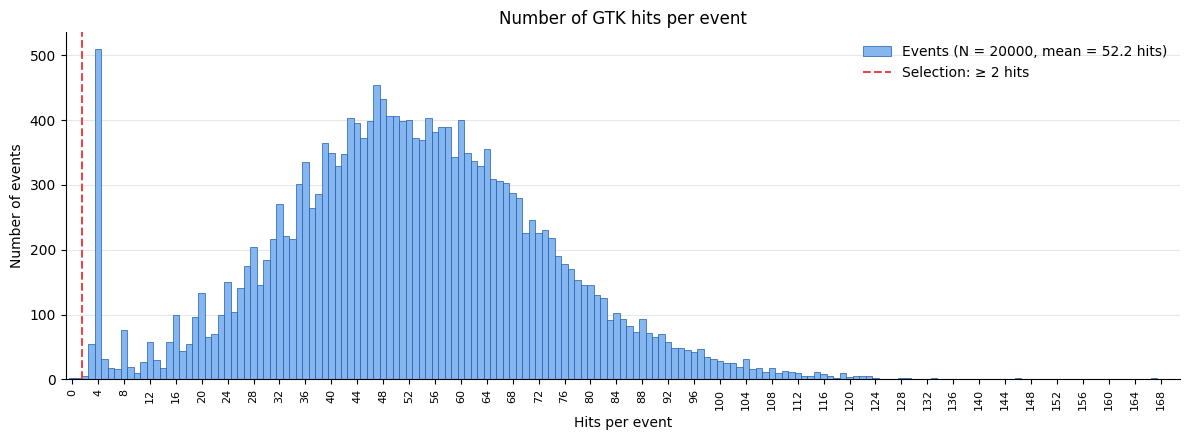

Events before selection:  20000
Rejected (< 2 hits):      5
Events after selection:   19995 (99.97%)


In [87]:
num_hits = ak.num(events.cl_x)
MIN_HITS = 2   # with 0 or 1 hit there is no pair to classify

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.hist(ak.to_numpy(num_hits), bins=np.arange(-0.5, ak.max(num_hits) + 1.5, 1),   # one bin per integer
        color="#86b6ef", edgecolor="#1c5cab", linewidth=0.5,
        label=f"Events (N = {len(num_hits)}, mean = {ak.mean(num_hits):.1f} hits)")
ax.axvline(MIN_HITS - 0.5, color="#e34948", linestyle="--", linewidth=1.5,       # boundary between 1 and 2 hits
           label=f"Selection: ≥ {MIN_HITS} hits")
ax.set_xticks(np.arange(0, ak.max(num_hits) + 1, 4))   # one track crossing the 4 stations = 4 hits
ax.tick_params(axis="x", labelsize=8, labelrotation=90)
ax.set_xlim(-1, ak.max(num_hits) + 1)
ax.set_xlabel("Hits per event")
ax.set_ylabel("Number of events")
ax.set_title("Number of GTK hits per event")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# Event selection
is_selected = num_hits >= MIN_HITS
num_before = len(events)
num_rejected = num_before - ak.sum(is_selected)
events = events[is_selected]

print(f"Events before selection:  {num_before}")
print(f"Rejected (< {MIN_HITS} hits):      {num_rejected}")
print(f"Events after selection:   {len(events)} ({100 * len(events) / num_before:.2f}%)")


### 1.4 Tracking as pair classification

All hit pairs (i, j) with i ≤ j: a pair is *connected* if the two hits belong to the same particle on consecutive stations.



Instead of building tracks directly, we ask a simpler question for **every pair of hits (i, j), with i ≤ j**: are they two consecutive hits of the same particle?
The answer is the label of the pair: **1 = connected**, **0 = not connected**. The model learns to predict these labels; the tracks are rebuilt from them in section 5.

**Rule.** Two hits are connected if they belong to the same particle (`cl_kinepart`) and one of them is on the **next station where that particle left a hit**.
A station without a hit of the particle is skipped, so every particle becomes a chain through its stations.

**Example.** An event with 5 hits and 2 particles:

| hit | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| `GTKstation` | 0 | 1 | 3 | 0 | 2 |
| `cl_kinepart` | 7 | 7 | 7 | 9 | 9 |

- Particle 7 has hits on GTK0, GTK1 and GTK3 (no hit on GTK2) → chain 0 → 1 → 2, i.e. pairs **(0, 1)** and **(1, 2)**. GTK2 is skipped.
- Particle 9 has hits on GTK0 and GTK2 → pair **(3, 4)**. GTK1 is skipped.

5 hits give 5 · 6 / 2 = **15 pairs**, in this order:

(0,0) (0,1) (0,2) (0,3) (0,4) (1,1) (1,2) (1,3) (1,4) (2,2) (2,3) (2,4) (3,3) (3,4) (4,4)

and only 3 of them are connected:

`labels = [0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0]`

Notes:
- If a particle has two hits on the same station (two neighbouring pixels), both are connected to the hits of the next station; the two hits are not connected to each other.


In [88]:
def build_ground_truth(station, kinepart):
    """Label of every hit pair (i, j) with i <= j: 1 = connected, 0 = not connected.

    Two hits are connected if they belong to the same particle and one of them is on
    the next station where that particle left a hit (missing stations are skipped).
    If a particle left more than one hit on the same station, all those hits are connected to the next station.
    """
    same_particle = (kinepart[:, None] == kinepart[None, :]) & (kinepart[:, None] >= 0)   # (N, N)
    later = station[None, :] > station[:, None]                                           # station_j > station_i

    # next_station[i]: first station after hit i where the same particle has a hit (inf if none)
    next_station = np.where(same_particle & later, station[None, :], np.inf).min(axis=1)

    adjacency = same_particle & (station[None, :] == next_station[:, None])
    adjacency = adjacency | adjacency.T              # the connection has no direction

    rows, cols = np.triu_indices(len(station))       # all pairs i <= j, including (i, i)
    pairs = np.stack([rows, cols], axis=1)           # (K, 2) with K = N (N + 1) / 2
    labels = adjacency[rows, cols].astype(np.int64)  # (K,)
    return pairs, labels


station = df["GTKstation"].to_numpy()
kinepart = df["cl_kinepart"].to_numpy()
pairs, labels = build_ground_truth(station, kinepart)

print(f"Hits in the event:   {len(df)}")
print(f"Pairs (i <= j):      {len(pairs)}")
print(f"Connected pairs:     {labels.sum()} ({100 * labels.mean():.1f}%)")

# The connected pairs of the event, one particle after the other
connected = pairs[labels == 1]
pd.DataFrame({
    "hit_i": connected[:, 0],
    "hit_j": connected[:, 1],
    "station_i": station[connected[:, 0]],
    "station_j": station[connected[:, 1]],
    "cl_kinepart": kinepart[connected[:, 0]],
}).sort_values(["cl_kinepart", "station_i"])



Hits in the event:   34
Pairs (i <= j):      595
Connected pairs:     25 (4.2%)


,hit_i,hit_j,station_i,station_j,cl_kinepart
6,6,15,0,1,0
15,15,23,1,2,0
21,23,31,2,3,0
0,0,9,0,1,14
9,9,18,1,2,14
18,18,27,2,3,14
2,2,11,0,1,26
11,11,20,1,2,26
3,3,12,0,1,64
12,12,21,1,2,64


### 1.5 Feature tensor

In [89]:
FEATURES = ["cl_x", "cl_y", "GTKstation", "cl_time"]   # input_dim = 4

def build_features(df):
    """Input of the model: one row per hit, one column per feature."""
    return torch.tensor(df[FEATURES].to_numpy(), dtype=torch.float32)   # (N, 4)


features = build_features(df)
labels = torch.from_numpy(labels)   # (K,) from section 1.4

print(f"features: {tuple(features.shape)}  -> (hits, features)")
print(f"labels:   {tuple(labels.shape)}  -> (pairs,) = N (N + 1) / 2 = {len(df) * (len(df) + 1) // 2}")
features[:5]


features: (34, 4)  -> (hits, features)
labels:   (595,)  -> (pairs,) = N (N + 1) / 2 = 595


tensor([[ 25.0646,   3.6876,   0.0000,  14.7526],
        [ 13.7699,   7.0023,   0.0000,   5.2554],
        [  4.2723,   8.5146,   0.0000,  17.3478],
        [  6.8425, -10.0887,   0.0000,  17.5806],
        [ 10.1387, -12.4930,   0.0000,   1.5630]])

### 1.6 Class imbalance

There are $N/4$ tracks, and each has 3 edges (0-1, 1-2, 2-3), so the number of connected pairs is $3N/4$. The total number of pairs is approximately $N^2/2$. Therefore, the fraction is $(3N/4) / (N^2/2) = 1.5/N$, which corresponds to $150/N$ as a percentage.

Pairs in 2000 events:  3203387
Connected:      79019 (2.47%)
Not connected:  3124368 (97.53%)
-> 1 connected pair every 41 pairs


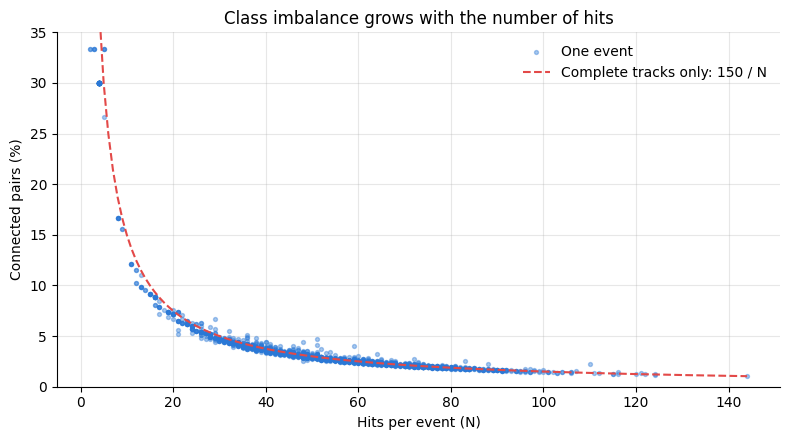

In [90]:
NUM_SAMPLE = 2000   # events used to estimate the class imbalance

num_hits_sample, num_pairs, num_connected = [], [], []
for index in range(NUM_SAMPLE):
    station = ak.to_numpy(events.GTKstation[index])
    kinepart = ak.to_numpy(events.cl_kinepart[index])
    _, event_labels = build_ground_truth(station, kinepart)
    num_hits_sample.append(len(station))
    num_pairs.append(len(event_labels))
    num_connected.append(event_labels.sum())
num_hits_sample, num_pairs, num_connected = np.array(num_hits_sample), np.array(num_pairs), np.array(num_connected)

total_pairs, total_connected = num_pairs.sum(), num_connected.sum()
print(f"Pairs in {NUM_SAMPLE} events:  {total_pairs}")
print(f"Connected:      {total_connected} ({100 * total_connected / total_pairs:.2f}%)")
print(f"Not connected:  {total_pairs - total_connected} ({100 * (1 - total_connected / total_pairs):.2f}%)")
print(f"-> 1 connected pair every {total_pairs / total_connected:.0f} pairs")

# Fraction of connected pairs in each event, as a function of its number of hits
hits_axis = np.arange(2, num_hits_sample.max() + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(num_hits_sample, 100 * num_connected / num_pairs, s=8, color="#2a78d6", alpha=0.4, label="One event")
ax.plot(hits_axis, 150 / hits_axis, color="#e34948", linestyle="--", linewidth=1.5,
        label="Complete tracks only: 150 / N")
ax.set_ylim(0, 35)
ax.set_xlabel("Hits per event (N)")
ax.set_ylabel("Connected pairs (%)")
ax.set_title("Class imbalance grows with the number of hits")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()



### 1.7 Train / validation / test split

In [91]:
split = config["data"]["split"]

# Shuffle the event indices once, with a fixed seed: the split is always the same
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(events))

num_train = int(split["train"] * len(events))
num_val = int(split["val"] * len(events))
split_indices = {
    "train": indices[:num_train],
    "val": indices[num_train:num_train + num_val],
    "test": indices[num_train + num_val:],
}

for name, event_indices in split_indices.items():
    print(f"{name:5s}: {len(event_indices):5d} events ({100 * len(event_indices) / len(events):.0f}%)")


train: 11997 events (60%)
val  :  3999 events (20%)
test :  3999 events (20%)


## 2. Dataset and DataLoader

### 2.1 Dataset

In [92]:
class GTKDataset(Dataset):
    """One item = one event: hit features, pair labels and the hit table."""

    def __init__(self, events, event_indices):
        self.events = events
        self.event_indices = event_indices

    def __len__(self):
        return len(self.event_indices)

    def __getitem__(self, idx):
        df = event_to_df(self.events, self.event_indices[idx])
        features = build_features(df)                                              # (N, 4)
        _, labels = build_ground_truth(df["GTKstation"].to_numpy(), df["cl_kinepart"].to_numpy())
        return features, torch.from_numpy(labels), df                              # labels: (K,)


datasets = {name: GTKDataset(events, event_indices) for name, event_indices in split_indices.items()} # dictionary comprehension

features, labels, df = datasets["train"][0]
print(f"train dataset: {len(datasets['train'])} events")
print(f"first event:   features {tuple(features.shape)}, labels {tuple(labels.shape)}, {labels.sum().item()} connected pairs")


train dataset: 11997 events
first event:   features (45, 4), labels (1035,), 32 connected pairs


### 2.2 Collate and padding


A batch must be a single rectangular tensor, but every event has a different number of hits.
The `collate_fn` makes the events of a batch the same size:

- **Features**: each event is padded with rows of zeros up to `max_len`, the largest number of hits in the batch → `(B, max_len, 4)`.
- **Labels**: every event uses the same list of pairs, all the pairs (i ≤ j) of `max_len` hits → `(B, max_len (max_len + 1) / 2)`.
  The pairs of real hits get their label (0 or 1). The pairs that involve a padding hit get the label `-100`.
- **`num_hits`**: the number of real hits of each event. The model uses it to ignore the padding hits (section 3.2).

Example with two events, A (3 hits) and B (5 hits): `max_len = 5`, so every event has 15 pairs.
For event A, only the 6 pairs between hits 0, 1 and 2 are real. The other 9 contain hit 3 or 4, which is padding, so they get `-100`.

Why `-100`? Both losses use `ignore_index=-100`: the padding pairs do not contribute to the loss.
Without it, the model would be trained on pairs that do not exist. In a typical batch they are more than half of all the pairs.

We could have paddedthe ground truth with one-hot rows `[0, 0]`. It looks harmless, but it is not equivalent to ignoring the pair.

**Example.** Event A has 3 hits, so 6 real pairs ( 3 real connection that we set to 1 + 3 self connections that we set to 0). Suppose the model gets each of them roughly right, with a loss of 0.1 per pair: the loss of the event should be **0.1**.
In a batch where the longest event has 5 hits, every event has 15 pairs, so event A gets 9 padding pairs.

1. **`[0, 0]` turned into a class with `argmax`** (what the original code did):
   `argmax([0, 0]) = 0`, so the 9 padding pairs become *"not connected"* pairs.
   The model is trained to classify pairs of zero-feature hits that do not exist.

2. **`[0, 0]` used directly as a one-hot target**:
   each padding pair contributes 0, but the mean still divides by all the pairs:

   | longest event in the batch | pairs per event | loss of event A |
   |---|---|---|
   | 5 hits  | 15 | 0.6 / 15 = **0.040** |
   | 10 hits | 55 | 0.6 / 55 = **0.011** |

   The same event, with the same predictions, gets a loss 4 to 9 times smaller depending on *which other events* are in its batch.
   The gradients are scaled in the same way: it is like a learning rate that changes randomly at every batch.

3. **`-100` with `ignore_index=-100`**:
   the padding pairs are removed from the sum **and** from the count, so the loss is 0.6 / 6 = **0.1** in every batch.

The Focal loss we use also requires class indices (0 or 1), not one-hot rows, so `-100` is the only option that works with both losses.


In [93]:
PAD_LABEL = -100   # label of the pairs that involve a padding hit: ignored by the loss

def collate_fn(batch):
    """Stack events with a different number of hits into one batch."""
    features, labels, dfs = zip(*batch)
    num_hits = torch.tensor([len(f) for f in features])           # (B,)
    max_len = int(num_hits.max())

    # Features: zero rows after the real hits -> (B, max_len, 4)
    padded_features = torch.zeros(len(batch), max_len, features[0].shape[1])
    # Labels: all pairs (i <= j) of max_len hits -> (B, max_len (max_len + 1) / 2)
    rows, cols = torch.triu_indices(max_len, max_len)
    padded_labels = torch.full((len(batch), len(rows)), PAD_LABEL)

    for b in range(len(batch)):
        padded_features[b, :num_hits[b]] = features[b]
        is_real_pair = cols < num_hits[b]                         # i <= j, so j real implies i real
        padded_labels[b, is_real_pair] = labels[b]

    return padded_features, padded_labels, num_hits, list(dfs)


loaders = {
    name: DataLoader(dataset, batch_size=config["data"]["batch_size"], shuffle=(name == "train"), collate_fn=collate_fn)
    for name, dataset in datasets.items()
}

features, labels, num_hits, dfs = next(iter(loaders["train"]))
print(f"hits per event: {num_hits.tolist()}")
print(f"features: {tuple(features.shape)}  -> (batch, max_len, features)")
print(f"labels:   {tuple(labels.shape)}  -> (batch, pairs of max_len hits)")
print(f"padding pairs: {100 * (labels == PAD_LABEL).float().mean():.0f}% of the batch")


hits per event: [48, 4, 52, 35, 32, 4, 49, 80, 62, 46, 31, 65, 81, 78, 32, 43, 45, 85, 70, 36, 42, 56, 28, 54, 21, 76, 31, 37, 79, 81, 36, 48]
features: (32, 85, 4)  -> (batch, max_len, features)
labels:   (32, 3655)  -> (batch, pairs of max_len hits)
padding pairs: 60% of the batch


## 3. The model

### 3.1 Encoder: embedding + self-attention + pair classifier

#### The padding mask

After the collate, every event of the batch has `max_len` hits, but only the first `num_hits[b]` are real: the others are rows of zeros.
The padding mask tells the attention which hits to ignore: **`True` = padding hit**, it receives no attention.

```python
padding_mask = torch.arange(max_len)[None, :] >= num_hits[:, None]   # (B, max_len)
```

**Example.** A batch with two events, A with 3 hits and B with 5 hits, so `max_len = 5`:

- `torch.arange(max_len)[None, :]` is the position of each hit, as a row: `[[0, 1, 2, 3, 4]]`
- `num_hits[:, None]` is the number of real hits of each event, as a column: `[[3], [5]]`
- comparing a row with a column compares every position with every event (broadcasting), giving a `(2, 5)` matrix:

| position | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| event A (3 hits) | False | False | False | **True** | **True** |
| event B (5 hits) | False | False | False | False | False |

Positions 3 and 4 of event A are padding: no hit of event A attends to them, so its output is the same as if it were alone, without padding (checked in section 3.3).
Event B is the longest of the batch and has no padding.


In [94]:
class Encoder(nn.Module):
    """Hit features -> one score per hit pair."""

    def __init__(self, config):
        super().__init__()
        model_config = config["model"]
        d_model = model_config["d_model"]

        # 1. Each hit (x, y, station, time) becomes a vector of size d_model
        self.embedding = nn.Linear(model_config["input_dim"], d_model)

        # 2. Self-attention: each hit looks at all the other hits of its event
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=model_config["num_head"],
            dim_feedforward=model_config["hidden_dim_classifier"],
            dropout=model_config["dropout"],
            batch_first=True,   # input is (batch, hits, d_model)
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, model_config["num_layers"],
                                                 enable_nested_tensor=False)   # avoids a PyTorch warning in eval


        # 3. Pair classifier: the two hit vectors, concatenated -> [not connected, connected]
        self.fc1 = nn.Linear(2 * d_model, 2 * d_model)
        self.fc2 = nn.Linear(2 * d_model, model_config["output_dim"])

    def forward(self, features, num_hits):
        """features: (B, max_len, 4), num_hits: (B,) -> logits (B, K, 2), K = max_len (max_len + 1) / 2"""
        max_len = features.shape[1]

        # True where the hit is padding: those hits receive no attention (section 3.2)
        padding_mask = torch.arange(max_len, device=features.device)[None, :] >= num_hits[:, None]   # (B, max_len)

        x = self.embedding(features)                                           # (B, max_len, d_model)
        x = self.transformer_encoder(x, src_key_padding_mask=padding_mask)     # (B, max_len, d_model)

        # All pairs (i <= j), same order as build_ground_truth and collate_fn
        rows, cols = torch.triu_indices(max_len, max_len, device=features.device)
        pairs = torch.cat([x[:, rows], x[:, cols]], dim=-1)                    # (B, K, 2 * d_model)

        return self.fc2(torch.relu(self.fc1(pairs)))                           # logits (B, K, 2)


model = Encoder(config)
print(f"Parameters: {sum(p.numel() for p in model.parameters())}")

logits = model(features, num_hits)   # the batch of section 2.2
print(f"features {tuple(features.shape)} -> logits {tuple(logits.shape)}")


Parameters: 21538
features (32, 85, 4) -> logits (32, 3655, 2)


### 3.2 Padding mask

Padding hits must not receive attention (`src_key_padding_mask`).

padding_mask: (32, 85)  -> (batch, max_len)
event 0 has 48 hits: 48 real positions, 37 padding positions
padding positions in the batch: 42%


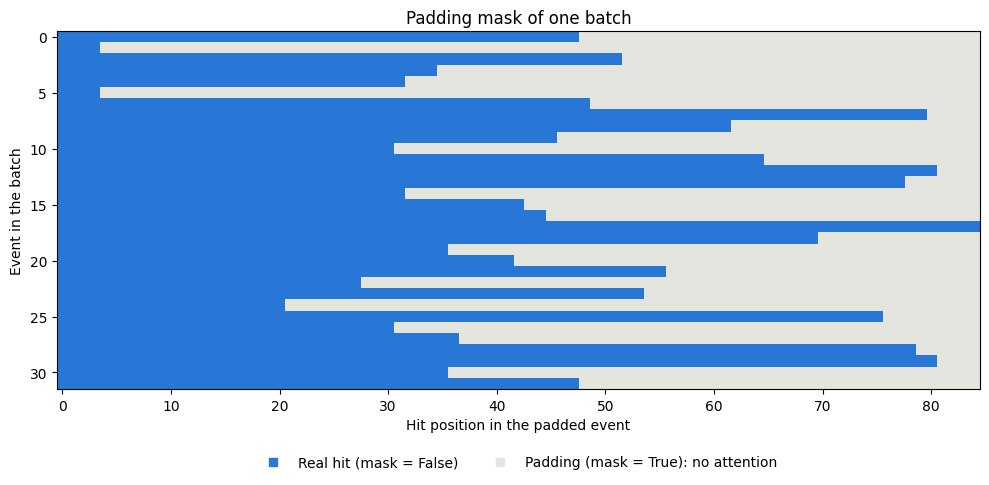

In [95]:
max_len = features.shape[1]
padding_mask = torch.arange(max_len)[None, :] >= num_hits[:, None]   # (B, max_len), True = padding

print(f"padding_mask: {tuple(padding_mask.shape)}  -> (batch, max_len)")
print(f"event 0 has {num_hits[0]} hits: {(~padding_mask[0]).sum()} real positions, {padding_mask[0].sum()} padding positions")
print(f"padding positions in the batch: {100 * padding_mask.float().mean():.0f}%")

# One row per event of the batch: real hits on the left, padding on the right
REAL_COLOR, PADDING_COLOR = (0.16, 0.47, 0.84), (0.90, 0.90, 0.88)
image = np.where(padding_mask[:, :, None], PADDING_COLOR, REAL_COLOR)   # (B, max_len, 3) RGB

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(image, aspect="auto", interpolation="nearest")
ax.plot([], [], marker="s", linestyle="", color=REAL_COLOR, label="Real hit (mask = False)")
ax.plot([], [], marker="s", linestyle="", color=PADDING_COLOR, label="Padding (mask = True): no attention")
ax.set_xlabel("Hit position in the padded event")
ax.set_ylabel("Event in the batch")
ax.set_title("Padding mask of one batch")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.show()


### 3.3 Sanity check: attention stays inside the event

The output of an event must depend **only on its own real hits**: not on the padding, and not on the other events of the batch.
We take the shortest event of a batch (the one with most padding), compute its output, then change something and measure how much its output changes.

| test | what we change | expected change of the output |
|---|---|---|
| 1 | the event alone, without padding | **0** |
| 2 | random noise instead of zeros in its padding rows | **0** |
| 3 | random noise in another event of the batch | **0** |
| 4 | one of its own hits moved by 5 mm | **> 0**, on all its pairs |

- Tests 1 and 2 check the **padding mask** (section 3.2).
- Test 3 checks that the events of a batch do not see each other (`batch_first=True`).
- Test 4 is the opposite check: the attention works. Moving one hit changes **every** pair of the event, also the pairs that do not contain that hit, because every hit attends to all the other hits of its event.


In [96]:
model.eval()   # no dropout: the output is deterministic

def event_logits(features, num_hits, b):
    """Logits of the real pairs of event b of the batch."""
    max_len = features.shape[1]
    _, cols = torch.triu_indices(max_len, max_len)
    with torch.no_grad():
        return model(features, num_hits)[b, cols < num_hits[b]]

b = int(num_hits.argmin())   # the shortest event of the batch: the one with most padding
n = int(num_hits[b])
reference = event_logits(features, num_hits, b)

# 1. The event alone, without padding
alone = event_logits(features[b:b + 1, :n], num_hits[b:b + 1], 0)

# 2. Noise instead of zeros in the padding rows of the event
noisy_padding = features.clone()
noisy_padding[b, n:] = torch.randn_like(noisy_padding[b, n:])

# 3. Another event of the batch replaced by noise
other_event = features.clone()
other_event[(b + 1) % len(features)] = torch.randn_like(features[0])

# 4. One hit of the same event moved by 5 mm in x
moved_hit = features.clone()
moved_hit[b, 0, 0] += 5.0
change = (event_logits(moved_hit, num_hits, b) - reference).abs().max(dim=-1).values   # one value per pair
rows, _ = torch.triu_indices(n, n)

print(f"Event {b} of the batch: {n} hits, {features.shape[1] - n} padding rows")
print("Max change of its output when...")
print(f"  1. the event is alone, without padding:    {(alone - reference).abs().max():.1e}")
print(f"  2. its padding rows are filled with noise: {(event_logits(noisy_padding, num_hits, b) - reference).abs().max():.1e}")
print(f"  3. another event of the batch changes:     {(event_logits(other_event, num_hits, b) - reference).abs().max():.1e}")
print(f"  4. one of its own hits is moved:           {change.max():.1e}")


Event 1 of the batch: 4 hits, 81 padding rows
Max change of its output when...
  1. the event is alone, without padding:    6.0e-08
  2. its padding rows are filled with noise: 0.0e+00
  3. another event of the batch changes:     0.0e+00
  4. one of its own hits is moved:           3.2e-02


### 3.4 LightningModule

Loss (Focal), padding pairs ignored (`ignore_index`), optimizer and scheduler.

In [97]:
class LightningEncoder(pl.LightningModule):
    """Encoder + loss + optimizer: everything the Trainer needs."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        self.model = Encoder(config)

        # Both losses skip the padding pairs (label = PAD_LABEL)
        if config["training"]["loss"] == "Focal":
            self.loss_fn = FocalLoss(gamma=2, ignore_index=PAD_LABEL)        # expects probabilities
        elif config["training"]["loss"] == "CrossEntropy":
            self.loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_LABEL)       # expects logits
        else:
            raise ValueError(f"Unknown loss: {config['training']['loss']}")

    def forward(self, features, num_hits):
        """Inference: probabilities [not connected, connected] for every pair, (B, K, 2)."""
        return torch.softmax(self.model(features, num_hits), dim=-1)

    def _step(self, batch, stage):
        features, labels, num_hits, _ = batch
        logits = self.model(features, num_hits)                              # (B, K, 2)

        scores = torch.softmax(logits, dim=-1) if self.config["training"]["loss"] == "Focal" else logits
        loss = self.loss_fn(scores.reshape(-1, 2), labels.reshape(-1))

        # Accuracy is useless with 97.5% of not-connected pairs: efficiency and purity of the connected ones
        predicted = logits.argmax(dim=-1) == 1
        true_positives = (predicted & (labels == 1)).sum()
        efficiency = true_positives / (labels == 1).sum().clamp(min=1)                       # found / true
        purity = true_positives / (predicted & (labels != PAD_LABEL)).sum().clamp(min=1)     # found / predicted

        self.log(f"{stage}_loss", loss, prog_bar=True, batch_size=len(features))
        self.log(f"{stage}_efficiency", efficiency, prog_bar=(stage == "val"), batch_size=len(features))
        self.log(f"{stage}_purity", purity, prog_bar=(stage == "val"), batch_size=len(features))
        return loss

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")

    def validation_step(self, batch, batch_idx):
        return self._step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self._step(batch, "test")

    def configure_optimizers(self):
        training_config = self.config["training"]
        optimizer = torch.optim.Adam(self.parameters(), lr=training_config["lr"])
        scheduler = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=training_config["lr_scheduler_step_size"], gamma=training_config["lr_scheduler_gamma"])
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}


lightning_model = LightningEncoder(config)

# One batch through the model, before any training
probabilities = lightning_model(features, num_hits)
loss = lightning_model.loss_fn(probabilities.reshape(-1, 2), labels.reshape(-1))
print(f"probabilities: {tuple(probabilities.shape)}, each row sums to {probabilities[0, 0].sum():.1f}")
print(f"{config['training']['loss']} loss on one batch, untrained model: {loss:.4f}")


probabilities: (32, 3655, 2), each row sums to 1.0
Focal loss on one batch, untrained model: 0.1247


### 3.5 Define ONNX Model

In [98]:
class EncoderONNX(nn.Module):
    """Same computation as Encoder, written so that it can be exported to ONNX.

    Differences with Encoder:
    - one event at a time, without padding: input (N, 4), no padding mask;
    - the pairs are an input (pair_indices), not built inside the model;
    - the attention is written by hand: nn.MultiheadAttention, once exported, only works for the N used in the export;
    - the output is already a probability (softmax included).
    """

    def __init__(self, config):
        super().__init__()
        model_config = config["model"]
        d_model = model_config["d_model"]
        self.num_head = model_config["num_head"]
        self.head_dim = d_model // self.num_head

        # Same layers and same names as Encoder: the trained weights can be loaded as they are.
        # transformer_encoder is used only as a container of weights, its forward is never called.
        self.embedding = nn.Linear(model_config["input_dim"], d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=model_config["num_head"],
            dim_feedforward=model_config["hidden_dim_classifier"],
            dropout=model_config["dropout"],
            batch_first=True,
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, model_config["num_layers"],
                                                         enable_nested_tensor=False)
        self.fc1 = nn.Linear(2 * d_model, 2 * d_model)
        self.fc2 = nn.Linear(2 * d_model, model_config["output_dim"])

    def encoder_layer(self, layer, x):
        """One nn.TransformerEncoderLayer by hand. x: (1, N, d_model). Every reshape uses -1 instead of N."""
        # Self-attention: in_proj_weight contains the query, key and value projections, one after the other
        q, k, v = F.linear(x, layer.self_attn.in_proj_weight, layer.self_attn.in_proj_bias).chunk(3, dim=-1)
        q = q.reshape(1, -1, self.num_head, self.head_dim).transpose(1, 2)                  # (1, heads, N, head_dim)
        k = k.reshape(1, -1, self.num_head, self.head_dim).transpose(1, 2)
        v = v.reshape(1, -1, self.num_head, self.head_dim).transpose(1, 2)

        weights = torch.softmax(q @ k.transpose(-2, -1) / self.head_dim ** 0.5, dim=-1)     # (1, heads, N, N)
        attention = (weights @ v).transpose(1, 2).reshape(1, -1, self.num_head * self.head_dim)   # (1, N, d_model)
        attention = layer.self_attn.out_proj(attention)

        # Residual + LayerNorm, then feed-forward + residual + LayerNorm
        x = layer.norm1(x + attention)
        return layer.norm2(x + layer.linear2(F.relu(layer.linear1(x))))

    def forward(self, features, pair_indices):
        """features: (N, 4), pair_indices: (K, 2) -> probabilities (1, K, 2)"""
        x = self.embedding(features.unsqueeze(0))                                           # (1, N, d_model)
        for layer in self.transformer_encoder.layers:
            x = self.encoder_layer(layer, x)
        pairs = torch.cat([x[:, pair_indices[:, 0]], x[:, pair_indices[:, 1]]], dim=-1)     # (1, K, 2 * d_model)
        return torch.softmax(self.fc2(torch.relu(self.fc1(pairs))), dim=-1)                 # (1, K, 2)


# Same weights as the Lightning model, then the same event through both models
onnx_model = EncoderONNX(config)
onnx_model.load_state_dict(lightning_model.model.state_dict())
onnx_model.eval()
lightning_model.eval()

event_features = features[0, :num_hits[0]]                                        # (N, 4): first event of the batch, no padding
pair_indices = torch.triu_indices(len(event_features), len(event_features)).T     # (K, 2)
with torch.no_grad():
    reference = lightning_model(event_features[None], num_hits[:1])
    output = onnx_model(event_features, pair_indices)

print(f"Encoder:     {tuple(reference.shape)}")
print(f"EncoderONNX: {tuple(output.shape)}")
print(f"Max difference: {(output - reference).abs().max():.1e}")


Encoder:     (1, 1176, 2)
EncoderONNX: (1, 1176, 2)
Max difference: 1.2e-07


check ONNX output

In [116]:
ONNX_PATH = "checkpoints/transformer.onnx"
extra = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CHECKPOINT_PATH = "checkpoints/Pretrained_model.ckpt"
pretrained_model = LightningEncoder.load_from_checkpoint(CHECKPOINT_PATH, config=config, map_location=DEVICE)
pretrained_model.eval()

# 1. The exportable model, with the weights of the trained model
onnx_model = EncoderONNX(config)
onnx_model.load_state_dict(pretrained_model.model.state_dict())
onnx_model.eval()

# 2. Export. The dummy input only fixes the types: the number of hits and of pairs is declared dynamic
dummy_features = torch.randn(3, config["model"]["input_dim"])
dummy_pairs = torch.triu_indices(3, 3).T
torch.onnx.export(
    onnx_model, (dummy_features, dummy_pairs), ONNX_PATH,
    input_names=["features", "pair_indices"],
    output_names=["probabilities"],
    dynamic_axes={"features": {0: "num_hits"}, "pair_indices": {0: "num_pairs"}, "probabilities": {1: "num_pairs"}},
    opset_version=17,
    **extra
)

# 3. Check: the ONNX file, run without PyTorch, gives the same probabilities on events of any size
session = onnxruntime.InferenceSession(ONNX_PATH)
max_difference = 0.0
for index in range(100):
    event_features, _, _ = datasets["test"][index]
    pair_indices = torch.triu_indices(len(event_features), len(event_features)).T
    onnx_output = session.run(None, {"features": event_features.numpy(), "pair_indices": pair_indices.numpy()})[0]
    with torch.no_grad():
        reference = pretrained_model(event_features[None], torch.tensor([len(event_features)]))
    max_difference = max(max_difference, np.abs(onnx_output - reference.numpy()).max())

print(f"Exported: {ONNX_PATH}")
print(f"Max difference with the PyTorch model on 100 test events: {max_difference:.1e}")


Exported: checkpoints/transformer.onnx
Max difference with the PyTorch model on 100 test events: 2.7e-05


## 4. Training

### 4.1 Callbacks and Trainer

In [100]:
training_config = config["training"]

# Keep the weights of the epoch with the best validation loss
checkpoint_callback = pl.callbacks.ModelCheckpoint(
    dirpath=training_config["checkpoint_dir"],
    filename="tutorial-{epoch:02d}-{val_loss:.4f}",
    monitor="val_loss", mode="min", save_top_k=1,
)

# Stop when the validation loss has not improved for `patience` epochs
early_stopping = pl.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=training_config["patience"])

# Write the logged metrics to a CSV file (read back in section 4.2)
logger = pl.loggers.CSVLogger(save_dir="logs", name="tutorial")

trainer = pl.Trainer(
    max_epochs=training_config["num_epochs"],
    accelerator=DEVICE,
    callbacks=[checkpoint_callback, early_stopping],
    logger=logger,
    log_every_n_steps=10,
)

trainer.fit(lightning_model, loaders["train"], loaders["val"])

print(f"Best checkpoint: {checkpoint_callback.best_model_path}")
print(f"Best val_loss:   {checkpoint_callback.best_model_score:.4f}")


GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/trainer/setup.py:177: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:654: Checkpoint directory /home/leonardo/Desktop/ML_GTK/Tutorial/checkpoints exists and is not empty.

  | Name    | Type      | Params | Mode
---------------------------------------------
0 | model   | Encoder   | 21.5 K | eval
1 | loss_fn | FocalLoss | 0      | eval
---------------------------------------------
21.5 K    Trainable params
0         Non-trainable params
21.5 K    Total params
0.086     Total estimated model params size (MB)
0         Modules in train mode
27        Modules in eval mode


/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.
/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Epoch 1: 100%|██████████| 375/375 [00:45<00:00,  8.28it/s, v_num=14, train_loss=0.0235, val_loss=0.0235, val_efficiency=0.000, val_purity=0.000]

`Trainer.fit` stopped: `max_epochs=2` reached.


Epoch 1: 100%|██████████| 375/375 [00:45<00:00,  8.28it/s, v_num=14, train_loss=0.0235, val_loss=0.0235, val_efficiency=0.000, val_purity=0.000]
Best checkpoint: /home/leonardo/Desktop/ML_GTK/Tutorial/checkpoints/tutorial-epoch=01-val_loss=0.0235.ckpt
Best val_loss:   0.0235


### 4.2 Loss and accuracy curves

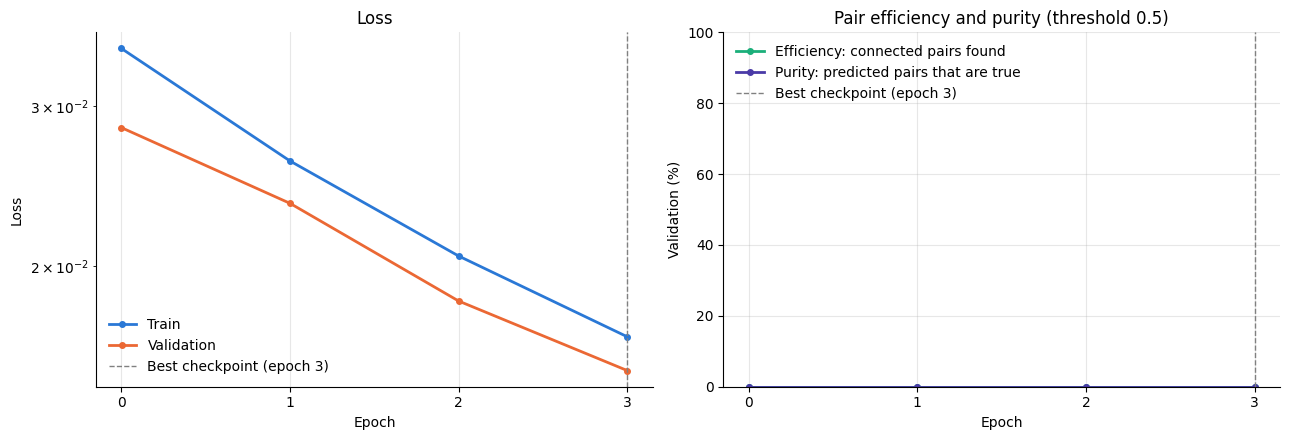

Best epoch: 3
val_loss          0.0153
val_efficiency    0.0000
val_purity        0.0000


In [101]:
# Curves of the long training done before the tutorial.
# For the training just run in section 4.1 use instead: f"{logger.log_dir}/metrics.csv"
METRICS_PATH = "/home/leonardo/Desktop/ML_GTK/Tutorial/logs/tutorial/version_9/metrics.csv"

# One row per logging step in the file -> one row per epoch (mean of the steps of that epoch)
metrics = pd.read_csv(METRICS_PATH).groupby("epoch").mean(numeric_only=True)
best_epoch = metrics["val_loss"].idxmin()

fig, (ax_loss, ax_metrics) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_loss.plot(metrics.index, metrics["train_loss"], color="#2a78d6", linewidth=2, marker="o", markersize=4, label="Train")
ax_loss.plot(metrics.index, metrics["val_loss"], color="#eb6834", linewidth=2, marker="o", markersize=4, label="Validation")
ax_loss.set_yscale("log")
ax_loss.set_ylabel("Loss")
ax_loss.set_title("Loss")

ax_metrics.plot(metrics.index, 100 * metrics["val_efficiency"], color="#1baf7a", linewidth=2, marker="o", markersize=4,
                label="Efficiency: connected pairs found")
ax_metrics.plot(metrics.index, 100 * metrics["val_purity"], color="#4a3aa7", linewidth=2, marker="o", markersize=4,
                label="Purity: predicted pairs that are true")
ax_metrics.set_ylim(0, 100)
ax_metrics.set_ylabel("Validation (%)")
ax_metrics.set_title("Pair efficiency and purity (threshold 0.5)")

for ax in (ax_loss, ax_metrics):
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"Best checkpoint (epoch {best_epoch})")
    ax.set_xlabel("Epoch")
    ax.set_xticks(metrics.index[::max(1, len(metrics) // 20)])   # at most ~20 ticks
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Best epoch: {best_epoch}")
print(metrics.loc[best_epoch, ["val_loss", "val_efficiency", "val_purity"]].round(4).to_string())


### 4.3 Pre-trained checkpoint

If you have no time or no GPU: download an already trained checkpoint and continue.

In [102]:
# Pre-trained model: 86 epochs on the full dataset.
# To use the model trained in section 4.1 instead: checkpoint_callback.best_model_path
CHECKPOINT_PATH = "checkpoints/Pretrained_model.ckpt"

lightning_model = LightningEncoder.load_from_checkpoint(CHECKPOINT_PATH, config=config, map_location=DEVICE)
lightning_model.eval()   # no dropout from here on: we only do inference

evaluator = pl.Trainer(accelerator=DEVICE, logger=False, enable_checkpointing=False)
validation_metrics = evaluator.validate(lightning_model, loaders["val"], verbose=False)[0]

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Validation loss:       {validation_metrics['val_loss']:.4f}")
print(f"Validation efficiency: {100 * validation_metrics['val_efficiency']:.1f}%")
print(f"Validation purity:     {100 * validation_metrics['val_purity']:.1f}%")


GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/trainer/setup.py:177: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
/home/leonardo/Desktop/ML_GTK/Tutorial/.venv/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


Validation DataLoader 0: 100%|██████████| 125/125 [00:05<00:00, 24.02it/s]
Checkpoint: checkpoints/Pretrained_model.ckpt
Validation loss:       0.0012
Validation efficiency: 97.1%
Validation purity:     98.0%


## 5. Post-processing and evaluation


### 5.1 Clustering of neighbouring hits

A particle can fire two neighbouring pixels on the same station. The track building (section 5.3) keeps **one point per station**, so before running the model we merge the hits that are close into a single point, a **cluster**.

Two hits are *close* if they are:
- on the **same station**,
- at most **0.85 mm** apart in (x, y): two 300 µm pixels touching at least by a corner,
- at most **0.75 ns** apart in time: 5 times the time resolution of a hit.

Closeness is not transitive: A close to B and B close to C must give one cluster {A, B, C}, even if A and C are not close.
`cluster_hits` handles this with **label propagation**: every hit starts with its own id, then repeatedly takes the **smallest id among its close hits**, until nothing changes.

**Example.** 4 hits on the same station: A–B close, B–C close, D isolated.

| step | A | B | C | D |
|---|---|---|---|---|
| start | 0 | 1 | 2 | 3 |
| 1 | 0 | 0 | 1 | 3 |
| 2 | 0 | 0 | 0 | 3 |
| 3 | 0 | 0 | 0 | 3 ← no change, stop |
| renumbered | 0 | 0 | 0 | 1 |

Result: 2 clusters, {A, B, C} and {D}.

`merge_clusters` then builds one row per cluster, with the **mean** of the features of its hits. The model works on the clusters; at the end (section 5.3) every cluster is mapped back to its original hits.

In this dataset 1.8% of the (particle, station) pairs have more than one hit, and clustering reduces the number of hits by about 3%.


In [103]:
DIST_THR = 2 * np.sqrt(2) * 0.3 + 1e-4   # mm: two 300 um pixels touching by a corner
TIME_THR = 5 * 0.150                     # ns: 5 times the time resolution of a hit

def cluster_hits(df, dist_thr=DIST_THR, time_thr=TIME_THR):
    """Group the hits that are close in space and time on the same station.

    Returns cluster_id (N,): hits with the same value belong to the same cluster.
    """
    xy, time, station = df[["cl_x", "cl_y"]].to_numpy(), df["cl_time"].to_numpy(), df["GTKstation"].to_numpy()
    close = ((np.linalg.norm(xy[:, None] - xy[None, :], axis=-1) <= dist_thr)
             & (np.abs(time[:, None] - time[None, :]) <= time_thr)
             & (station[:, None] == station[None, :]))                       # (N, N)

    # Chains of close hits form one cluster: each hit takes the smallest id among its neighbours, until nothing changes
    cluster_id = np.arange(len(df))
    while True:
        smallest = np.where(close, cluster_id[None, :], len(df)).min(axis=1)
        if (smallest == cluster_id).all():
            break
        cluster_id = smallest
    return np.unique(cluster_id, return_inverse=True)[1]                     # renumbered 0 ... C-1


def merge_clusters(df, cluster_id):
    """One row per cluster: the mean of the features of its hits."""
    return df[FEATURES].groupby(cluster_id).mean()


# An event of the validation set with at least one cluster of two hits
EXAMPLE_EVENT = 2   # a validation event with a cluster of two hits: the example of sections 5.1-5.4

_, _, df = datasets["val"][EXAMPLE_EVENT]
cluster_id = cluster_hits(df)
clustered_df = merge_clusters(df, cluster_id)

print(f"Validation event {EXAMPLE_EVENT}: {len(df)} hits -> {len(clustered_df)} clusters")
is_merged = np.bincount(cluster_id)[cluster_id] > 1
display(df.assign(cluster_id=cluster_id)[is_merged])              # the hits that are merged
print(f"Clusters of the event: {len(clustered_df)}")
display(clustered_df.loc[np.unique(cluster_id[is_merged])])       # the resulting clusters


Validation event 2: 36 hits -> 35 clusters


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,cluster_id
27,10.251000,2.8819,30.031763,3,38,27
28,10.551001,2.5819,29.897316,3,38,27


Clusters of the event: 35


,cl_x,cl_y,GTKstation,cl_time
27,10.401001,2.7319,3.0,29.964539


### 5.2 From scores to edges

The model gives every pair of clusters (i ≤ j) a **score**: the probability that the two clusters are consecutive hits of the same particle.
A pair is kept as an **edge** if its score is above a threshold.

This is done in two steps:
1. `predict_scores` runs the model **once** on the event and returns all the pairs with their scores.
2. The threshold is a single comparison, `scores > THRESHOLD`, so it can be changed without running the model again (section 5.6 tries 11 thresholds).

**Example** (illustrative scores). An event with 3 clusters, one per station, gives 3 · 4 / 2 = 6 pairs:

| pair | (0,0) | (0,1) | (0,2) | (1,1) | (1,2) | (2,2) |
|---|---|---|---|---|---|---|
| stations | 0–0 | 0–1 | 0–2 | 1–1 | 1–2 | 2–2 |
| score | 0.01 | **0.87** | 0.12 | 0.01 | **0.91** | 0.01 |

- threshold 0.5 → edges (0, 1) and (1, 2): the chain GTK0 → GTK1 → GTK2.
- threshold 0.1 → also (0, 2), which skips GTK1. A lower threshold keeps more true edges, but also more wrong ones; section 5.3 resolves the conflict by keeping, for every cluster, only its best edge.

The threshold 0.5 used here is provisional: the best value is chosen on the validation set in section 5.6.


In [104]:
def predict_scores(model, clustered_df):
    """Run the model on one event: all cluster pairs (i <= j) and their probability of being connected."""
    features = build_features(clustered_df)[None]                  # (1, C, 4): a batch with one event
    num_hits = torch.tensor([len(clustered_df)])
    with torch.no_grad():
        probabilities = model(features, num_hits)                  # (1, K, 2)
    rows, cols = np.triu_indices(len(clustered_df))
    return np.stack([rows, cols], axis=1), probabilities[0, :, 1].numpy()


THRESHOLD = 0.5   # provisional: the best value is chosen in section 5.6

pairs, scores = predict_scores(lightning_model, clustered_df)
is_edge = scores > THRESHOLD
edges, edge_scores = pairs[is_edge], scores[is_edge]

print(f"Clusters:               {len(clustered_df)}")
print(f"Pairs:                  {len(pairs)}")
print(f"Edges (score > {THRESHOLD}):   {len(edges)}")

# The edges of the event: which clusters the model connects, and how confident it is
station = clustered_df["GTKstation"].to_numpy().astype(int)
pd.DataFrame({
    "cluster_i": edges[:, 0],
    "cluster_j": edges[:, 1],
    "station_i": station[edges[:, 0]],
    "station_j": station[edges[:, 1]],
    "score": edge_scores.round(3),
})


Clusters:               35
Pairs:                  630
Edges (score > 0.5):   27


,cluster_i,cluster_j,station_i,station_j,score
0,0,8,0,1,0.859
1,1,9,0,1,0.868
2,2,10,0,1,0.892
3,3,11,0,1,0.872
4,4,12,0,1,0.895
5,5,13,0,1,0.894
6,6,15,0,1,0.853
7,7,16,0,1,0.911
8,8,17,1,2,0.855
9,9,18,1,2,0.873


### 5.3 From edges to tracks

The edges above threshold are not yet tracks: a cluster can have several edges, some of them wrong.
`build_tracks` turns them into chains, using one physical constraint: **a particle crosses each station once**, so every cluster has at most one edge towards the next station and one edge from the previous one.

1. **Orient** every edge from the lower to the higher station (edges inside one station are dropped).
2. Every cluster keeps only its **best outgoing** edge (highest score).
3. Every cluster keeps only its **best incoming** edge.
4. **Follow the chains**, starting from the clusters without incoming edges.

**Example** (illustrative scores). 5 clusters: 0 on GTK0, 1 on GTK1, 2 and 4 on GTK2, 3 on GTK3. Edges above threshold:

| edge | 0 → 1 | 0 → 2 | 1 → 2 | 2 → 3 | 4 → 3 |
|---|---|---|---|---|---|
| score | 0.87 | 0.12 | 0.91 | 0.85 | 0.30 |
| after step 2 (best outgoing) | ✓ | ✗ (0 → 1 is better) | ✓ | ✓ | ✓ |
| after step 3 (best incoming) | ✓ | | ✓ | ✓ | ✗ (2 → 3 is better) |

Chains: cluster 0 has no incoming edge, so the track starts there: **0 → 1 → 2 → 3**. Cluster 4 is left without edges and belongs to no track.
(The pair (3, 4) comes out of the model with cluster 3 first, because pairs are ordered by index; step 1 turns it into 4 → 3, from GTK2 to GTK3.)

Then:
- `select_tracks` keeps only the tracks usable by the experiment: hits on **GTK3, GTK2 and at least one of GTK0 and GTK1**.
- `clusters_to_hits` replaces every cluster with its original hits, so that a track can be compared with the truth (section 5.4).


In [105]:
def build_tracks(edges, edge_scores, station):
    """Edges between clusters -> tracks (lists of clusters, from the first to the last station)."""
    # 1. Every edge goes from the lower to the higher station; edges inside one station are dropped
    forward = station[edges[:, 0]] <= station[edges[:, 1]]
    table = pd.DataFrame({
        "source": np.where(forward, edges[:, 0], edges[:, 1]),
        "target": np.where(forward, edges[:, 1], edges[:, 0]),
        "score": edge_scores,
    })
    table = table[station[table["source"]] < station[table["target"]]]

    # 2. A particle crosses each station once: every cluster keeps only its best outgoing edge...
    table = table.sort_values("score", ascending=False, kind="stable").drop_duplicates("source")
    # 3. ... and only its best incoming edge
    table = table.drop_duplicates("target")

    # 4. Follow the chains source -> target, starting from the clusters without incoming edge
    next_cluster = dict(zip(table["source"], table["target"]))
    tracks = []
    for start in sorted(set(next_cluster) - set(next_cluster.values())):
        track = [start]
        while track[-1] in next_cluster:
            track.append(next_cluster[track[-1]])
        tracks.append(track)
    return tracks


def select_tracks(tracks, station):
    """Keep the tracks usable by the experiment: GTK3, GTK2 and at least one of GTK0 and GTK1."""
    selected = []
    for track in tracks:
        stations = set(station[track])
        if 3 in stations and 2 in stations and (0 in stations or 1 in stations):
            selected.append(track)
    return selected


def clusters_to_hits(tracks, cluster_id):
    """Tracks of clusters -> tracks of original hits (a cluster may contain more than one hit)."""
    return [sorted(np.flatnonzero(np.isin(cluster_id, track)).tolist()) for track in tracks]


station = clustered_df["GTKstation"].to_numpy().astype(int)
cluster_tracks = build_tracks(edges, edge_scores, station)
selected_tracks = select_tracks(cluster_tracks, station)
predicted_tracks = clusters_to_hits(selected_tracks, cluster_id)

print(f"Edges:               {len(edges)}")
print(f"Tracks:              {len(cluster_tracks)}")
print(f"Tracks selected:     {len(selected_tracks)}")
for track in predicted_tracks:
    print(f"  hits {track}  stations {df['GTKstation'].to_numpy()[track].tolist()}")


Edges:               27
Tracks:              9
Tracks selected:     9
  hits [0, 8, 17, 26]  stations [0, 1, 2, 3]
  hits [1, 9, 18, 27, 28]  stations [0, 1, 2, 3, 3]
  hits [2, 10, 19, 29]  stations [0, 1, 2, 3]
  hits [3, 11, 20, 30]  stations [0, 1, 2, 3]
  hits [4, 12, 21, 31]  stations [0, 1, 2, 3]
  hits [5, 13, 22, 32]  stations [0, 1, 2, 3]
  hits [6, 15, 24, 34]  stations [0, 1, 2, 3]
  hits [7, 16, 25, 35]  stations [0, 1, 2, 3]
  hits [14, 23, 33]  stations [1, 2, 3]


### 5.4 Matching with true tracks: TP, FP, FN

In [106]:
def true_tracks(df):
    """Tracks of the true particles, with the same selection as the predicted ones (GTK3, GTK2, GTK0 or GTK1)."""
    tracks = []
    for _, hits in df[df["cl_kinepart"] >= 0].groupby("cl_kinepart"):
        stations = set(hits["GTKstation"])
        if 3 in stations and 2 in stations and (0 in stations or 1 in stations):
            tracks.append(sorted(hits.index.tolist()))
    return tracks


def count_matches(predicted_tracks, gt_tracks):
    """A predicted track is correct only if it contains exactly the hits of a true track."""
    predicted = {tuple(track) for track in predicted_tracks}
    true = {tuple(track) for track in gt_tracks}
    true_positives = len(predicted & true)     # predicted and true
    false_positives = len(predicted - true)    # predicted but not true (fake tracks)
    false_negatives = len(true - predicted)    # true but not predicted (lost tracks)
    return true_positives, false_positives, false_negatives


gt_tracks = true_tracks(df)
tp, fp, fn = count_matches(predicted_tracks, gt_tracks)

print(f"True tracks:      {len(gt_tracks)}")
print(f"Predicted tracks: {len(predicted_tracks)}")
print(f"TP = {tp} (correct), FP = {fp} (fake), FN = {fn} (lost)")


True tracks:      9
Predicted tracks: 9
TP = 9 (correct), FP = 0 (fake), FN = 0 (lost)


### 5.5 Efficiency, purity, fake rate, F1

In [107]:
def evaluate(model, dataset, thresholds):
    """TP, FP and FN summed over all the events of the dataset, for each threshold: array (len(thresholds), 3)."""
    counts = np.zeros((len(thresholds), 3), dtype=int)
    for index in tqdm(range(len(dataset)), desc="Evaluating events"):
        _, _, df = dataset[index]
        gt_tracks = true_tracks(df)

        # Clustering and model: once per event
        cluster_id = cluster_hits(df)
        clustered_df = merge_clusters(df, cluster_id)
        station = clustered_df["GTKstation"].to_numpy().astype(int)
        pairs, scores = predict_scores(model, clustered_df)

        # Threshold -> edges -> tracks -> comparison with the truth: once per threshold
        for t, threshold in enumerate(thresholds):
            is_edge = scores > threshold
            tracks = select_tracks(build_tracks(pairs[is_edge], scores[is_edge], station), station)
            counts[t] += count_matches(clusters_to_hits(tracks, cluster_id), gt_tracks)
    return counts


def track_metrics(counts, thresholds):
    """Efficiency, purity, fake tracks and F1 score (in %) from the TP, FP, FN of each threshold."""
    tp, fp, fn = counts.T
    efficiency = tp / (tp + fn)      # fraction of the true tracks that are reconstructed
    purity = tp / (tp + fp)          # fraction of the reconstructed tracks that are true
    fake_tracks = fp / (tp + fn)     # fake tracks per true track
    f1 = 2 * efficiency * purity / (efficiency + purity)
    return pd.DataFrame({
        "threshold": thresholds, "TP": tp, "FP": fp, "FN": fn,
        "efficiency": 100 * efficiency, "purity": 100 * purity,
        "fake_tracks": 100 * fake_tracks, "f1": 100 * f1,
    }).round(2)



# The whole validation set, with the provisional threshold
counts = evaluate(lightning_model, datasets["val"], [THRESHOLD])
track_metrics(counts, [THRESHOLD])


Evaluating events:   0%|          | 0/3999 [00:00<?, ?it/s]

Evaluating events: 100%|██████████| 3999/3999 [00:10<00:00, 391.52it/s]


,threshold,TP,FP,FN,efficiency,purity,fake_tracks,f1
0,0.5,44809,688,1875,95.98,98.49,1.47,97.22


### 5.6 Threshold choice on validation, result on test

Evaluating events: 100%|██████████| 3999/3999 [00:31<00:00, 128.26it/s]


,threshold,TP,FP,FN,efficiency,purity,fake_tracks,f1
0,0.01,45543,849,1141,97.56,98.17,1.82,97.86
1,0.05,45542,835,1142,97.55,98.20,1.79,97.88
2,0.10,45536,810,1148,97.54,98.25,1.74,97.90
3,0.15,45515,785,1169,97.50,98.30,1.68,97.90
4,0.20,45485,763,1199,97.43,98.35,1.63,97.89
5,0.30,45385,730,1299,97.22,98.42,1.56,97.81
6,0.40,45235,714,1449,96.90,98.45,1.53,97.66
7,0.50,44809,688,1875,95.98,98.49,1.47,97.22
8,0.60,43658,663,3026,93.52,98.50,1.42,95.95
9,0.70,39422,620,7262,84.44,98.45,1.33,90.91


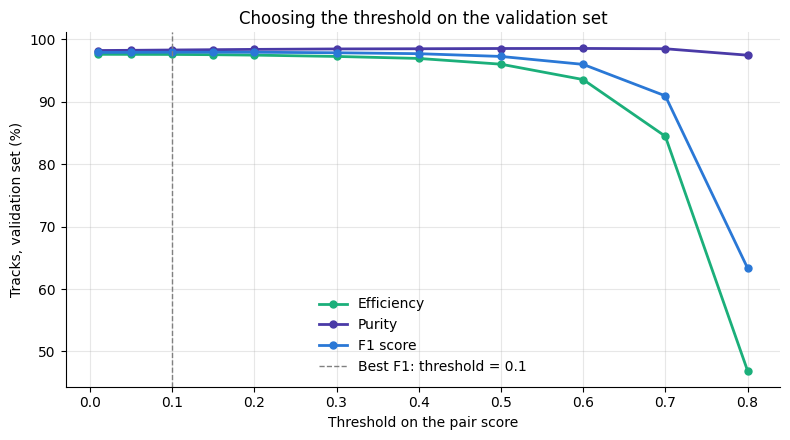

Evaluating events: 100%|██████████| 3999/3999 [00:10<00:00, 390.67it/s]

Best threshold on the validation set: 0.1


,threshold,TP,FP,FN,efficiency,purity,fake_tracks,f1
0,0.1,46133,852,1151,97.57,98.19,1.8,97.88


In [108]:
THRESHOLDS = [0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

# 1. Scan the thresholds on the VALIDATION set and keep the one with the best F1 score
validation_metrics = track_metrics(evaluate(lightning_model, datasets["val"], THRESHOLDS), THRESHOLDS)
best_threshold = validation_metrics.loc[validation_metrics["f1"].idxmax(), "threshold"]
display(validation_metrics)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(validation_metrics["threshold"], validation_metrics["efficiency"], color="#1baf7a", linewidth=2, marker="o", markersize=5, label="Efficiency")
ax.plot(validation_metrics["threshold"], validation_metrics["purity"], color="#4a3aa7", linewidth=2, marker="o", markersize=5, label="Purity")
ax.plot(validation_metrics["threshold"], validation_metrics["f1"], color="#2a78d6", linewidth=2, marker="o", markersize=5, label="F1 score")
ax.axvline(best_threshold, color="gray", linestyle="--", linewidth=1, label=f"Best F1: threshold = {best_threshold}")
ax.set_xlabel("Threshold on the pair score")
ax.set_ylabel("Tracks, validation set (%)")
ax.set_title("Choosing the threshold on the validation set")
ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

# 2. Final result: the TEST set, never used so far, with the threshold chosen on the validation set
test_metrics = track_metrics(evaluate(lightning_model, datasets["test"], [best_threshold]), [best_threshold])
print(f"Best threshold on the validation set: {best_threshold}")
display(test_metrics)


## 6. Output Analysis

### 6.1 Score distribution of the two classes

How well does the model separate the connected pairs from the others? We collect the score of every real pair in 20 validation batches (about one million pairs) and draw one histogram per class:

- **blue**: pairs that are *not connected* (label 0), which should be close to 0;
- **orange**: pairs that are *connected* (label 1), which should be close to 1;
- **grey line**: the threshold chosen in section 5.6.

The y axis is logarithmic: there are about 40 times more not-connected pairs, so on a linear scale the orange histogram would be invisible.
Here we use the original hits, without clustering, so that the labels of section 1 match the scores directly.

The two numbers printed below the plot are the errors made by the threshold alone:
- **lost edges**: connected pairs below the threshold;
- **fake edges**: not-connected pairs above the threshold.

A fake-edge rate below 1% looks small, but it is a fraction of a very large number: there are about one fake edge every four or five true edges above threshold.
The tracks are still very pure (section 5.6) because the track building of section 5.3 keeps only the best outgoing and the best incoming edge of every cluster, and drops most of the fake ones.


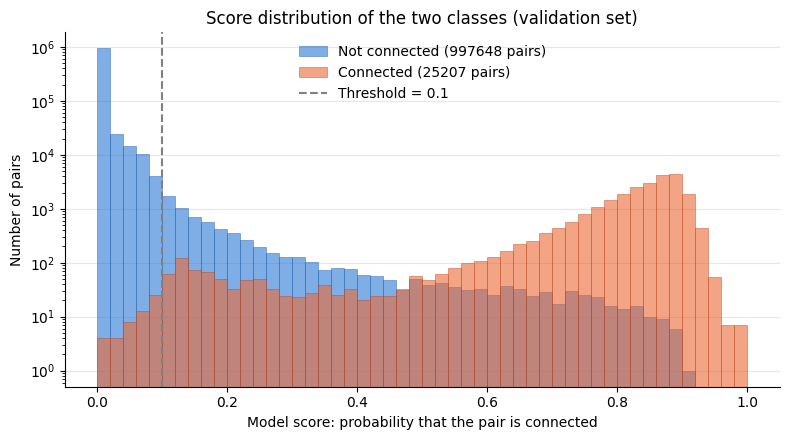

Connected pairs below the threshold (lost edges):     0.21%
Not connected pairs above the threshold (fake edges): 0.68%


In [109]:
NUM_BATCHES = 20   # validation batches used for the histogram

all_scores, all_labels = [], []
with torch.no_grad():
    for batch_index, (features, labels, num_hits, _) in enumerate(loaders["val"]):
        if batch_index == NUM_BATCHES:
            break
        scores = lightning_model(features, num_hits)[:, :, 1]     # (B, K): probability of "connected"
        is_real = labels != PAD_LABEL                              # padding pairs are dropped
        all_scores.append(scores[is_real])
        all_labels.append(labels[is_real])
all_scores, all_labels = torch.cat(all_scores).numpy(), torch.cat(all_labels).numpy()

bins = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(all_scores[all_labels == 0], bins=bins, color="#2a78d6", alpha=0.6, edgecolor="#1c5cab", linewidth=0.5,
        label=f"Not connected ({(all_labels == 0).sum()} pairs)")
ax.hist(all_scores[all_labels == 1], bins=bins, color="#eb6834", alpha=0.6, edgecolor="#b8451b", linewidth=0.5,
        label=f"Connected ({(all_labels == 1).sum()} pairs)")
ax.axvline(best_threshold, color="gray", linestyle="--", linewidth=1.5, label=f"Threshold = {best_threshold}")
ax.set_yscale("log")
ax.set_xlabel("Model score: probability that the pair is connected")
ax.set_ylabel("Number of pairs")
ax.set_title("Score distribution of the two classes (validation set)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center")
plt.tight_layout()
plt.show()

print(f"Connected pairs below the threshold (lost edges):     {100 * (all_scores[all_labels == 1] <= best_threshold).mean():.2f}%")
print(f"Not connected pairs above the threshold (fake edges): {100 * (all_scores[all_labels == 0] > best_threshold).mean():.2f}%")


### 6.2 Finding events with errors

In [110]:
def reconstruct_event(model, df, threshold):
    """The whole chain of section 5 on one event: hits -> predicted tracks (lists of hits)."""
    cluster_id = cluster_hits(df)
    clustered_df = merge_clusters(df, cluster_id)
    station = clustered_df["GTKstation"].to_numpy().astype(int)
    pairs, scores = predict_scores(model, clustered_df)
    is_edge = scores > threshold
    tracks = select_tracks(build_tracks(pairs[is_edge], scores[is_edge], station), station)
    return clusters_to_hits(tracks, cluster_id)


# TP, FP and FN of every event of the test set
rows = []
for index in tqdm(range(len(datasets["test"])), desc="Reconstructing events"):
    _, _, df = datasets["test"][index]
    gt_tracks = true_tracks(df)
    tp, fp, fn = count_matches(reconstruct_event(lightning_model, df, best_threshold), gt_tracks)
    rows.append({"event": index, "hits": len(df), "true_tracks": len(gt_tracks), "TP": tp, "FP": fp, "FN": fn})
event_results = pd.DataFrame(rows)

# The events with at least one fake or lost track, the worst first
error_events = event_results[(event_results["FP"] + event_results["FN"]) > 0]
error_events = error_events.sort_values(["FN", "FP"], ascending=False)

print(f"Events of the test set:               {len(event_results)}")
print(f"Events with all the tracks correct:   {len(event_results) - len(error_events)} ({100 * (1 - len(error_events) / len(event_results)):.1f}%)")
print(f"Events with at least one wrong track: {len(error_events)} ({100 * len(error_events) / len(event_results):.1f}%)")
error_events.head(10)


Reconstructing events: 100%|██████████| 3999/3999 [00:10<00:00, 385.57it/s]

Events of the test set:               3999
Events with all the tracks correct:   3133 (78.3%)
Events with at least one wrong track: 866 (21.7%)


,event,hits,true_tracks,TP,FP,FN
2456,2456,82,15,8,5,7
2468,2468,116,27,21,3,6
643,643,95,22,17,2,5
3290,3290,84,20,15,2,5
57,57,89,19,15,3,4
309,309,119,23,19,3,4
772,772,109,25,21,3,4
1018,1018,57,12,8,3,4
3189,3189,96,22,18,3,4
3247,3247,56,12,8,3,4


### 6.3 Interactive 3D display: true, predicted and fake tracks

In [111]:
event_index = int(error_events.iloc[0]["event"])   # the worst event of the test set; try other rows of error_events

_, _, df = datasets["test"][event_index]
predicted_tracks = reconstruct_event(lightning_model, df, best_threshold)
gt_tracks = true_tracks(df)
false_positive_tracks = [track for track in predicted_tracks if track not in gt_tracks]

print(f"Test event {event_index}: {len(df)} hits, {len(gt_tracks)} true tracks, "
      f"{len(predicted_tracks)} predicted tracks, {len(false_positive_tracks)} fake")
utilities.plot_3d_interactive_clean(predicted_tracks, gt_tracks, false_positive_tracks, df)


Test event 2456: 82 hits, 15 true tracks, 13 predicted tracks, 5 fake


In [112]:
# The hits behind every fake track: what the model predicted, and what the truth is
for track in false_positive_tracks:
    particles = df.loc[track, "cl_kinepart"].unique()               # true particles of the hits of the predicted track
    truth = df[df["cl_kinepart"].isin(particles)].copy()            # all the hits of those particles
    truth["in_predicted_track"] = truth.index.isin(track)

    print(f"Predicted track (hits): {track}")
    print(f"True particles involved: {particles.tolist()}")
    display(truth.sort_values(["cl_kinepart", "GTKstation"]))


Predicted track (hits): [2, 18, 41, 57]
True particles involved: [55]


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,in_predicted_track
2,10.467501,5.506585,31.893814,0,55,True
18,10.498816,5.625850,31.759186,1,55,True
41,9.549180,4.335010,32.056469,2,55,True
57,9.051001,2.581900,31.707485,3,55,True
58,8.151000,2.581900,32.136612,3,55,False
59,8.151000,2.281900,32.178413,3,55,False


Predicted track (hits): [5, 21, 48, 77]
True particles involved: [20, 41]


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,in_predicted_track
5,-16.940660,0.442205,19.106684,0,20,True
21,-16.907816,0.553250,19.144146,1,20,True
48,-15.157660,-1.350170,19.465254,2,20,True
79,-10.549000,-2.218100,19.446878,3,20,False
12,-18.197861,-4.056170,19.408659,0,41,False
34,-18.163666,-3.945500,19.547596,1,41,False
52,-16.960901,-4.049090,20.088333,2,41,False
77,-13.249000,-1.018100,19.224159,3,41,True


Predicted track (hits): [11, 29, 51, 75]
True particles involved: [36]


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,in_predicted_track
11,-8.544980,-2.268715,32.827557,0,36,True
27,-10.910934,-1.852750,32.605957,1,36,False
28,-11.210935,-1.852450,33.184410,1,36,False
29,-8.511325,-2.155150,32.829643,1,36,True
30,-10.311324,-2.153350,32.964741,1,36,False
31,-9.711715,-2.453950,32.621201,1,36,False
32,-10.011715,-2.453650,32.911449,1,36,False
33,-10.311714,-2.453350,33.022266,1,36,False
51,-7.660540,-3.754670,33.073433,2,36,True
75,-4.949000,-3.418100,32.784962,3,36,True


Predicted track (hits): [13, 35, 53, 61, 62]
True particles involved: [46]


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,in_predicted_track
13,-6.749300,-4.971055,14.422743,0,46,True
35,-6.715225,-5.156950,14.652156,1,46,True
53,-6.411620,-4.655420,14.113464,2,46,True
61,-5.249000,0.481900,14.247889,3,46,True
62,-4.949000,0.181900,14.185119,3,46,True
64,-7.849000,2.281900,14.469226,3,46,False
65,-7.249000,1.981900,14.323311,3,46,False
66,-7.549000,1.981900,14.491118,3,46,False
67,-7.849000,1.981900,14.298606,3,46,False
68,-6.949000,1.681900,14.095164,3,46,False


Predicted track (hits): [14, 36, 37, 38, 49, 78]
True particles involved: [48, 102]


,cl_x,cl_y,cl_time,GTKstation,cl_kinepart,in_predicted_track
14,-18.943541,-1.355195,20.817434,0,48,True
36,-18.910156,-1.244750,21.168415,1,48,True
37,-18.910545,-1.544750,20.838827,1,48,True
49,-17.258741,-2.248910,21.139700,2,48,True
78,-12.648999,-1.618100,21.219877,3,48,True
15,-19.244020,-1.654805,22.223803,0,102,False
38,-19.210936,-1.844450,21.911074,1,102,True
50,-17.858740,-2.248550,22.093735,2,102,False
70,-13.549000,0.781900,21.686682,3,102,False


### 6.4 Attention maps

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
GTKstation,0,0,0,0,0,0,0,1,1,1,...,2,2,2,2,3,3,3,3,3,3
cl_kinepart,0,38,40,28,18,18,43,0,38,40,...,40,28,18,43,0,38,40,28,18,43


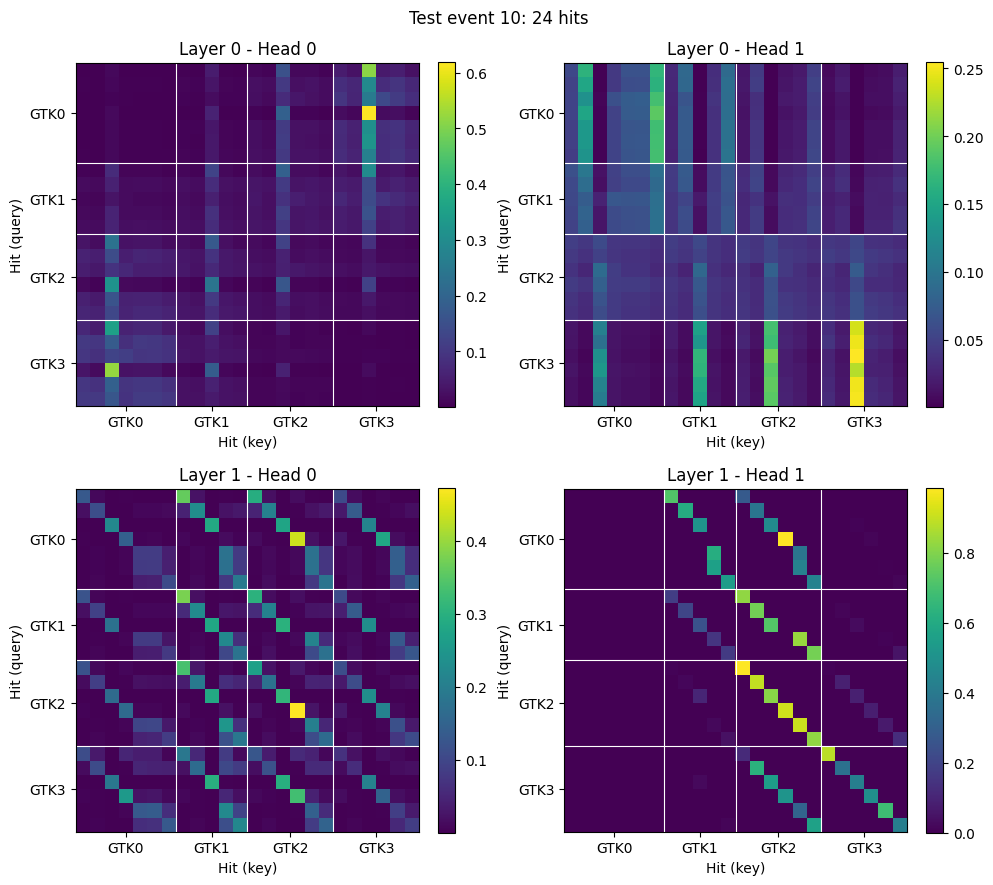

In [113]:
def attention_maps(model, df):
    """Attention weights of one event: {layer: (heads, N, N)}. Row = hit that looks, column = hit that is looked at."""
    encoder = model.model
    maps = {}
    with torch.no_grad():
        x = encoder.embedding(build_features(df)[None])                    # (1, N, d_model)
        for index, layer in enumerate(encoder.transformer_encoder.layers):
            # The layer does not return its attention weights: we ask its attention block directly
            _, weights = layer.self_attn(x, x, x, need_weights=True, average_attn_weights=False)
            maps[index] = weights[0]                                       # (heads, N, N)
            x = layer(x)                                                   # input of the next layer
    return maps


event_index = 10   # a small, clean event of the test set (24 hits, 6 particles): try others

_, _, df = datasets["test"][event_index]
attention = attention_maps(lightning_model, df)

display(df[["GTKstation", "cl_kinepart"]].T)   # which hits belong to the same particle
utilities.plot_attention_maps(attention, df, title=f"Test event {event_index}: {len(df)} hits")


### 6.5 Failure analysis: where are the tracks lost?

Looking at single events (section 6.3) shows *what* goes wrong. Here we look at **all the true tracks of the test set** to find *when* it goes wrong.
For every true track we record whether it was reconstructed, and two properties:

- **hits in the event**: how crowded the event is;
- **max hits of the particle on one station**: 1 in the normal case (one hit per station), more when the particle fires several pixels on the same station.

`efficiency_by` groups the tracks by one of these properties and computes, for each group, the fraction of reconstructed tracks and its binomial uncertainty √(p (1 − p) / n). The number of tracks of each group is written under the axis: groups with few tracks have large error bars.

**Results** (pre-trained model, threshold 0.1):

| hits in the event | efficiency |   | max hits on one station | efficiency |
|---|---|---|---|---|
| 0–20 | 99.1% |   | 1 | 98.2% |
| 40–60 | 97.9% |   | 2 | 90.5% |
| 80–100 | 96.4% |   | 3 | 88.7% |
| 100–200 | 94.4% |   | 4 or more | 81.2% |

Two critical cases:

1. **Crowded events.** With more hits there are more wrong pairs that look plausible, and the efficiency drops by about 5 points.
2. **Several hits on the same station.** This is the strongest effect. These tracks are only 6% of all the true tracks, but 30% of the lost ones.
   The cause is in the post-processing more than in the model: the track building keeps one cluster per station, and a track counts as correct only if it contains *exactly* the true hits. If the clustering of section 5.1 does not merge all the hits of the particle, the track is lost even when the model connected the stations correctly.

The remaining 70% of the lost tracks have one hit per station: this analysis does not explain them, and they have to be inspected event by event with section 6.3.


Analysing true tracks: 100%|██████████| 3999/3999 [00:16<00:00, 236.34it/s]


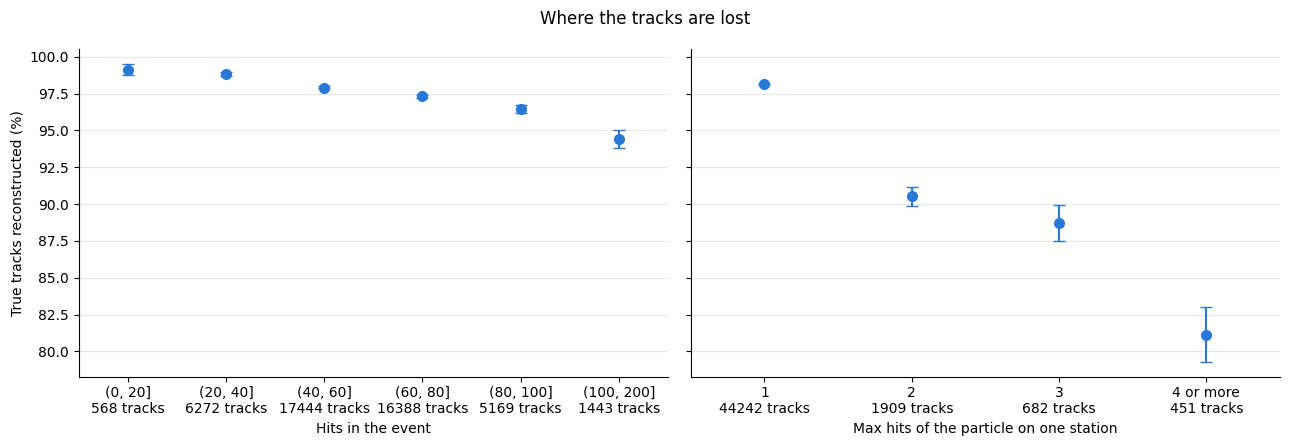

True tracks: 47284, lost: 1151 (2.43%)
Lost tracks with more than one hit on a station: 30% (they are 6% of all the true tracks)


In [114]:
# For every true track of the test set: was it reconstructed, and in which conditions?
rows = []
for index in tqdm(range(len(datasets["test"])), desc="Analysing true tracks"):
    _, _, df = datasets["test"][index]
    predicted = {tuple(track) for track in reconstruct_event(lightning_model, df, best_threshold)}
    for track in true_tracks(df):
        hits_per_station = df.loc[track, "GTKstation"].value_counts()
        rows.append({
            "event": index,
            "event_hits": len(df),
            "max_hits_on_a_station": hits_per_station.max(),   # 1 = one hit per station
            "found": tuple(track) in predicted,
        })
track_results = pd.DataFrame(rows)


def efficiency_by(groups):
    """Efficiency (%) and its binomial uncertainty for each group of true tracks."""
    table = track_results.groupby(groups, observed=True)["found"].agg(tracks="size", efficiency="mean")
    table["uncertainty"] = 100 * np.sqrt(table["efficiency"] * (1 - table["efficiency"]) / table["tracks"])
    table["efficiency"] = 100 * table["efficiency"]
    return table.round(2)

by_event_size = efficiency_by(pd.cut(track_results["event_hits"], [0, 20, 40, 60, 80, 100, 200]))
by_multiplicity = efficiency_by(track_results["max_hits_on_a_station"].clip(upper=4))
by_multiplicity.index = ["1", "2", "3", "4 or more"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, table, xlabel in [(axes[0], by_event_size, "Hits in the event"),
                          (axes[1], by_multiplicity, "Max hits of the particle on one station")]:
    positions = np.arange(len(table))
    ax.errorbar(positions, table["efficiency"], yerr=table["uncertainty"], color="#2a78d6",
                marker="o", markersize=7, linestyle="", capsize=4, label="Track efficiency (test set)")
    ax.set_xticks(positions, [f"{label}\n{tracks} tracks" for label, tracks in zip(table.index, table["tracks"])])
    ax.set_xlim(-0.5, len(table) - 0.5)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("True tracks reconstructed (%)")
# axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("Where the tracks are lost")
plt.tight_layout()
plt.show()

lost = track_results[~track_results["found"]]
print(f"True tracks: {len(track_results)}, lost: {len(lost)} ({100 * len(lost) / len(track_results):.2f}%)")
print(f"Lost tracks with more than one hit on a station: {100 * (lost['max_hits_on_a_station'] > 1).mean():.0f}% "
      f"(they are {100 * (track_results['max_hits_on_a_station'] > 1).mean():.0f}% of all the true tracks)")
